---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group OISCDivisiKaggle

- Nathan Adhika Santosa (13524041)
- Renuno Yuqa Frinardi (13524080)
- Timothy Bernard Soeharto (13524092)
- Valentino Daniel Kusumo (13524104)
- Leonardus Brain Fatolosja (13524146)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification**](#12)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

This dataset contains hotel booking records used to predict whether a
reservation will be canceled (`is_canceled = 1`) or not (`is_canceled = 0`).
Accurate predictions can help hotels forecast room demand, manage
cancellation risks, and plan operational strategies as well as guest offers.
The analysis uses booking attributes, guest characteristics, arrival
schedules, booking channels, booking history, nightly rates, and special
requests.

## Aim

The aim of this assignment is to build and compare several classification
models—both from-scratch implementations and benchmark library models—to
accurately predict booking cancellations on the validation and test sets.

## Metric

The primary metric used is accuracy, as it follows standard classification evaluation. Because the target distribution is imbalanced (around 67% non-canceled and 33% canceled), the positive-class F1-score, along with precision and recall, is also used to evaluate how well each model detects canceled bookings.


## Dataset

The data is split into `train.csv` and `test.csv`. `train.csv` contains 19
columns, including the target `is_canceled`, whereas `test.csv` contains 18
predictor columns without the target. The `id` column is read as a string
and excluded from the model features.
Nominal features such as `meal_package`, `room_category`, and
`booking_channel` have no inherent ordering and are one-hot encoded. Binary
features are represented by `0` and `1`, while guest counts, length of stay,
lead time, nightly rates, booking history, and special requests are treated
as numeric features.

## Approach

The workflow consists of a stratified train-validation split, data quality
analysis, data cleaning, missing-value imputation, numeric feature
standardization, one-hot encoding of categorical features, validation across
multiple models, hyperparameter tuning, best-model selection, and Kaggle
submission generation. All preprocessing statistics are computed strictly on
the training data to prevent *data leakage* from the validation or test sets.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
%pip install numpy pandas matplotlib qpsolvers osqp scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd

import sys
from IPython.display import display
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from inspect import signature
from sklearn.metrics import f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression as SklearnLR
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support



## Settings

Paths and shared constants are kept in this class.

In [55]:
class Settings:
    ROOT = next(
        (path for path in (Path.cwd(), *Path.cwd().parents)
         if (path / "src" / "notebook.ipynb").is_file() and (path / "dataset").is_dir()),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError("Start the notebook from the repository root or src/.")

    SEED = 42
    DATA_DIR = ROOT / "dataset"
    OUTPUT_DIR = Path(os.environ.get("MAIN_OUTPUT_DIR", ROOT / "output"))
    TARGET = "is_canceled"
    ID = "id"

CFG = Settings()
if str(CFG.ROOT) not in sys.path:
    sys.path.insert(0, str(CFG.ROOT))
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Import Local Algorithms
from src.decision_tree import DecisionTree
from src.decision_tree.optimized.decision_tree import DecisionTree as OptimizedTree
from src.decision_tree.tree_visualization import plot_decision_tree
from src.logistic_regression.logistic_regression import LogisticRegression
from src.logistic_regression.optimized import LROptimized
from src.svm.svm import SVM
from src.svm.visualizer import plot_svm_2d
from src.naive_bayes import NaiveBayes
from src.knn.knn import KNN

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    return np.random.default_rng(seed)

split_rng = seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [4]:
train_df = pd.read_csv(CFG.DATA_DIR / "train.csv", dtype={'id': str})
test_df = pd.read_csv(CFG.DATA_DIR / "test.csv", dtype={'id': str})

# Data cleaning dasar yang semantik: nilai tanpa tamu dewasa tidak valid,
# sedangkan nilai 0 pada harga hanya diperlakukan sebagai missing bila
# booking bukan Complimentary.
for frame in (train_df, test_df):
    frame.loc[frame["num_adults"].eq(0), "num_adults"] = np.nan
    missing_rate = frame["nightly_rate_idr"].eq(0) & frame["booking_channel"].ne("Complimentary")
    frame.loc[missing_rate, "nightly_rate_idr"] = np.nan

print(f'Train: {train_df.shape}  Test: {test_df.shape}')


Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding<a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [5]:
display(pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "columns": [train_df.shape[1], test_df.shape[1]],
}, index=["train", "test"]))
display(train_df.head())

describe_features = train_df.drop(columns=[CFG.ID, CFG.TARGET])
describe_numeric = describe_features.select_dtypes(include="number").columns
display(pd.DataFrame({
    "role": ["ID" if col == CFG.ID else "target" if col == CFG.TARGET
             else "numeric" if col in describe_numeric else "categorical"
             for col in train_df.columns],
    "dtype": train_df.dtypes.astype(str),
    "unique_values": train_df.nunique(),
}))

display(describe_features.describe(include="number").T)
display(describe_features.select_dtypes(exclude="number").describe().T)

,rows,columns
train,27373,19
test,6844,18


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


,role,dtype,unique_values
id,ID,str,27373
num_adults,numeric,float64,4
num_children,numeric,float64,6
weekend_nights,numeric,int64,8
weekday_nights,numeric,int64,18
meal_package,categorical,str,4
needs_parking,numeric,float64,2
room_category,categorical,str,7
days_before_arrival,numeric,float64,407
arrival_year,numeric,int64,2


,count,mean,std,min,25%,50%,75%,max
num_adults,26458.0,1.852634e+00,0.505644,1.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


,count,unique,top,freq
meal_package,25613,4,Breakfast,19654
room_category,26371,7,Type B,20447
booking_channel,27373,5,Online Travel Agent,17511


## Explore Data

This part covers distributions and relationships between attributes.

,count,share
is_canceled,,
0,18404,0.672341
1,8969,0.327659


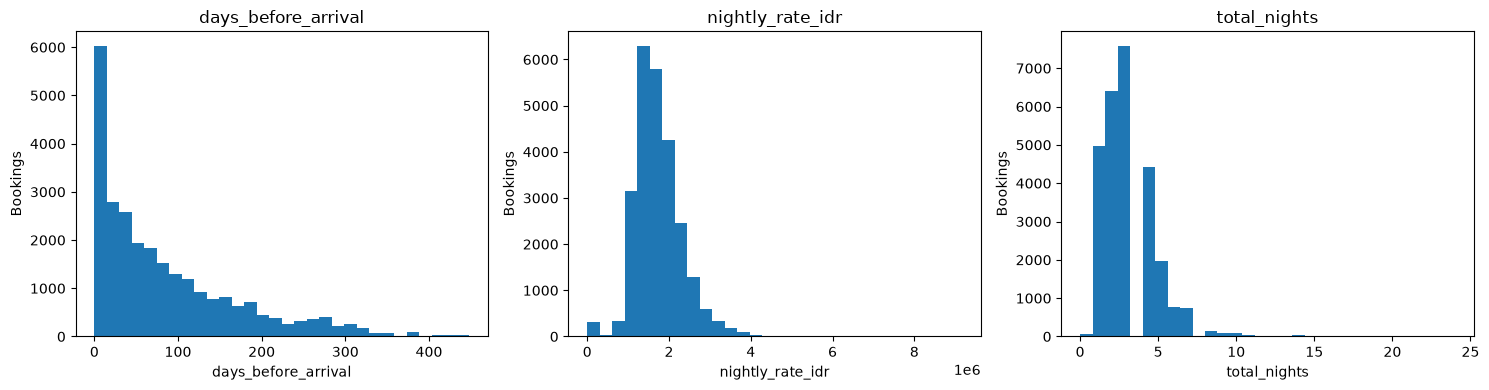

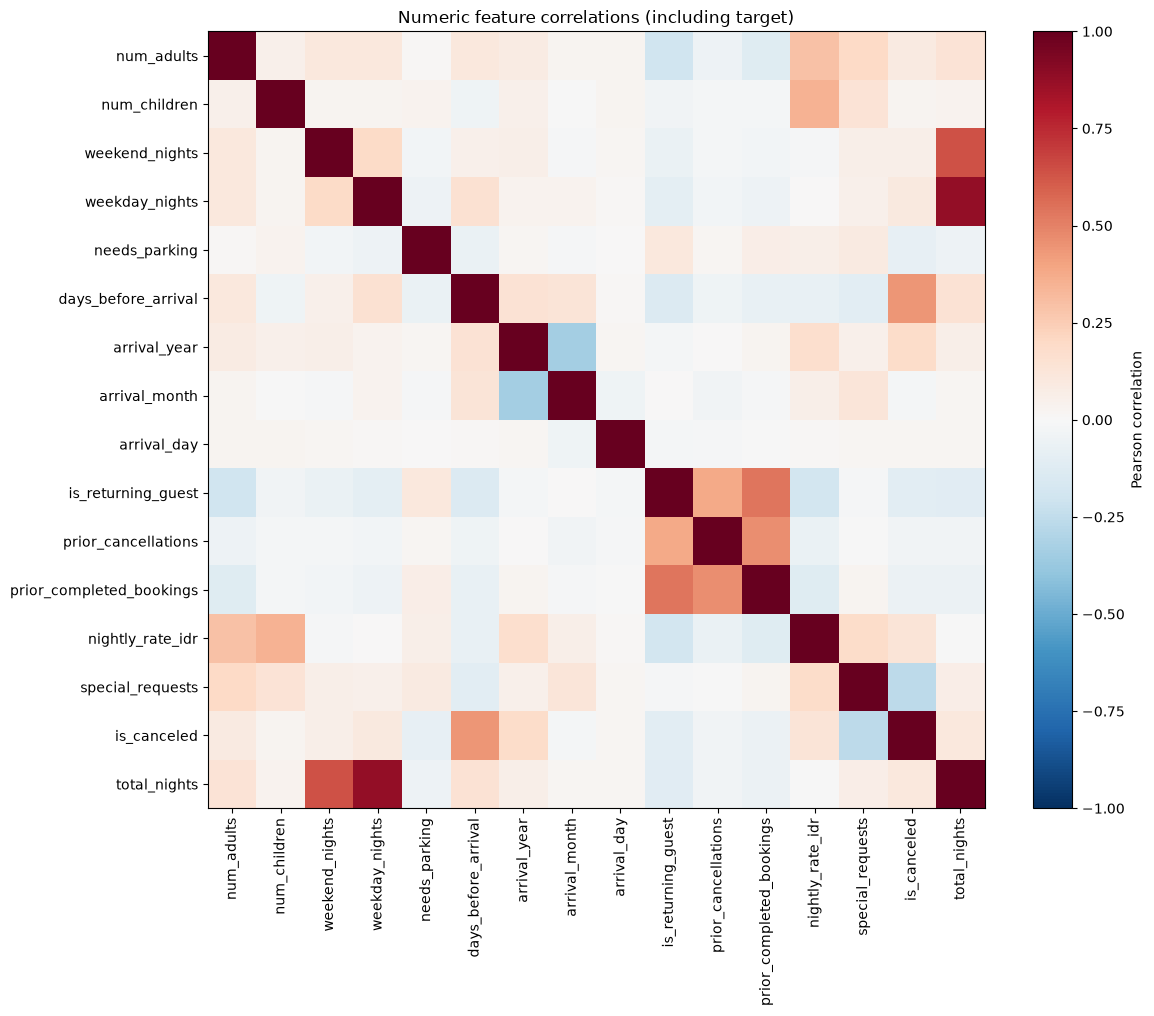

In [6]:
# Target Distribution
display(train_df[CFG.TARGET].value_counts().sort_index().to_frame("count").assign(
    share=lambda counts: counts["count"] / counts["count"].sum(),
))


# Numeric Feature Distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["days_before_arrival", "nightly_rate_idr", "total_nights"]):
    if column == "total_nights":
        (train_df["weekday_nights"] + train_df["weekend_nights"]).plot.hist(bins=30, ax=ax)
    else:
        train_df[column].plot.hist(bins=30, ax=ax)
    ax.set(title=column, xlabel=column, ylabel="Bookings")
fig.tight_layout()
plt.show()

# Pearson Correlation between Numeric Features
plt.figure(figsize=(12, 10))
plt.imshow(train_df.assign(
    total_nights=train_df["weekday_nights"] + train_df["weekend_nights"],
).drop(columns=CFG.ID).corr(numeric_only=True), vmin=-1, vmax=1, cmap="RdBu_r")
plt.xticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"], rotation=90,
)
plt.yticks(
    range(len(train_df.select_dtypes(include="number").columns) + 1),
    [*train_df.select_dtypes(include="number").columns, "total_nights"],
)
plt.title("Numeric feature correlations (including target)")
plt.colorbar(label="Pearson correlation")
plt.tight_layout()
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [7]:
# Missing values
display(pd.concat({
    "train": pd.DataFrame({"count": train_df.isna().sum(), "percent": train_df.isna().mean().mul(100)}),
    "test": pd.DataFrame({"count": test_df.isna().sum(), "percent": test_df.isna().mean().mul(100)}),
}, axis=1).round(2))

# Duplicate
display(pd.DataFrame({
    name: {
        f"{CFG.ID} missing": frame[CFG.ID].isna().sum(),
        f"{CFG.ID} duplicate": frame[CFG.ID].dropna().duplicated().sum(),
        "Rows with duplicates": frame.duplicated().sum(),
        "Repeated Predicator": frame.duplicated(subset=test_df.columns.drop(CFG.ID)).sum(),
    }
    for name, frame in (("train", train_df), ("test", test_df))
}))

# Zero Value
for name, frame in (("train", train_df), ("test", test_df)):
    print(name)
    display(pd.Series({
        "num_adults = 0": frame["num_adults"].eq(0).sum(),
        "weekday_nights + weekend_nights = 0": (frame["weekday_nights"] + frame["weekend_nights"]).eq(0).sum(),
        "nightly_rate_idr = 0": frame["nightly_rate_idr"].eq(0).sum(),
        "arrival_year/month/day not valid or empty": pd.to_datetime({
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        }, errors="coerce").isna().sum(),
    }))
    display(pd.Series({
        column: (frame[column].notna() & ~frame[column].isin([0, 1])).sum()
        for column in ("needs_parking", "is_returning_guest")
    }, name="Values other than 0/1 (without missing)"))


train           test        
                         count percent  count percent
id                           0    0.00    0.0    0.00
num_adults                 915    3.34  202.0    2.95
num_children              3035   11.09  747.0   10.91
weekend_nights               0    0.00    0.0    0.00
weekday_nights               0    0.00    0.0    0.00
meal_package              1760    6.43  442.0    6.46
needs_parking             1082    3.95  247.0    3.61
room_category             1002    3.66  242.0    3.54
days_before_arrival       1123    4.10  290.0    4.24
arrival_year                 0    0.00    0.0    0.00
arrival_month                0    0.00    0.0    0.00
arrival_day                  0    0.00    0.0    0.00
booking_channel              0    0.00    0.0    0.00
is_returning_guest           0    0.00    0.0    0.00
prior_cancellations          0    0.00    0.0    0.00
prior_completed_bookings     0    0.00    0.0    0.00
nightly_rate_idr          2184    7.98  566.0    8.27
special_requests          2500    9.13  593.0    8.66
is_canceled                  0    0.00    NaN     NaN

,train,test
id missing,0,0
id duplicate,0,0
Rows with duplicates,0,0
Repeated Predicator,66,3


train


num_adults = 0                                 0
weekday_nights + weekend_nights = 0           64
nightly_rate_idr = 0                         267
arrival_year/month/day not valid or empty      0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Values other than 0/1 (without missing), dtype: int64

test


num_adults = 0                                0
weekday_nights + weekend_nights = 0           9
nightly_rate_idr = 0                         59
arrival_year/month/day not valid or empty     0
dtype: int64

needs_parking         0
is_returning_guest    0
Name: Values other than 0/1 (without missing), dtype: int64

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [8]:
train_set, val_set = train_test_split(
    train_df,
    test_size = 0.2,
    stratify = train_df[CFG.TARGET],
    random_state = CFG.SEED
)

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [9]:
X_train = train_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
X_val = val_set.drop(columns=[CFG.ID, CFG.TARGET]).copy()
y_train = train_set[CFG.TARGET].copy()
y_val = val_set[CFG.TARGET].copy()

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [10]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
categorical_columns = X_train.columns.difference(numeric_columns, sort=False).tolist()

missing_imputer = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True), numeric_columns),
    ("categorical", SimpleImputer(strategy="constant", fill_value="<missing>", keep_empty_features=True), categorical_columns),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train = missing_imputer.fit_transform(X_train)
X_val = missing_imputer.transform(X_val)

### Duplicates

This part covers repeated records.

In [11]:
# [No duplicate handling due to lack of duplicates in the dataset]
display(pd.Series({
    "train_duplicate_rows": train_set.duplicated().sum(),
    "validation_duplicate_rows": val_set.duplicated().sum(),
    "train_repeated_predictors": train_set.drop(columns=[CFG.ID, CFG.TARGET]).duplicated().sum(),
}, name="count"))


train_duplicate_rows          0
validation_duplicate_rows     0
train_repeated_predictors    41
Name: count, dtype: int64

### Outliers

This part covers values far from the rest of the data.

In [12]:
# [Doesn't handle outliers, due to lack of outliers]
display(X_train[numeric_columns].describe(percentiles=[0.01, 0.5, 0.99]).T[
    ["min", "1%", "50%", "99%", "max"]
])


,min,1%,50%,99%,max
num_adults,1.0,1.0,2.0,3.00,4.0
num_children,0.0,0.0,0.0,2.00,10.0
weekend_nights,0.0,0.0,1.0,2.00,7.0
weekday_nights,0.0,0.0,2.0,6.00,17.0
needs_parking,0.0,0.0,0.0,1.00,1.0
days_before_arrival,0.0,0.0,57.0,342.03,448.0
arrival_year,2023.0,2023.0,2024.0,2024.00,2024.0
arrival_month,1.0,1.0,8.0,12.00,12.0
arrival_day,1.0,1.0,16.0,31.00,31.0
is_returning_guest,0.0,0.0,0.0,1.00,1.0


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [13]:
# Check for data errors in the raw dataset after basic semantic cleaning
def audit_data_errors(frame):
    binary_columns = ["needs_parking", "is_returning_guest"]
    invalid_binary = pd.Series({
        column: int((frame[column].notna() & ~frame[column].isin([0, 1])).sum())
        for column in binary_columns
    })

    valid_dates = pd.to_datetime(
        {
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        },
        errors="coerce",
    )

    report = pd.Series({
        "num_adults_zero": int(frame["num_adults"].eq(0).sum()),
        "zero_nights": int((frame["weekday_nights"].fillna(0) +
                            frame["weekend_nights"].fillna(0)).eq(0).sum()),
        "zero_rate_non_complimentary": int(
            (frame["nightly_rate_idr"].eq(0) &
             frame["booking_channel"].ne("Complimentary")).sum()
        ),
        "invalid_or_missing_arrival_date": int(valid_dates.isna().sum()),
    })
    return report, invalid_binary

for name, frame in (("train", train_df), ("test", test_df)):
    report, invalid_binary = audit_data_errors(frame)
    print(name)
    display(report.to_frame("count"))
    display(invalid_binary.to_frame("invalid_values"))

# Zero values in num_adults have already been converted to missing so they
# are handled by the median imputer. Zero rates for Complimentary bookings
# are retained because they carry valid domain meaning.


train


,count
num_adults_zero,0
zero_nights,64
zero_rate_non_complimentary,0
invalid_or_missing_arrival_date,0


,invalid_values
needs_parking,0
is_returning_guest,0


test


,count
num_adults_zero,0
zero_nights,9
zero_rate_non_complimentary,0
invalid_or_missing_arrival_date,0


,invalid_values
needs_parking,0
is_returning_guest,0


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [14]:
def construct_features(frame):
    frame = frame.copy()
    frame["total_nights"] = frame["weekday_nights"] + frame["weekend_nights"]
    frame["total_guests"] = frame["num_adults"].fillna(0) + frame["num_children"].fillna(0)
    frame["weekend_night_ratio"] = (
        frame["weekend_nights"] / frame["total_nights"].replace(0, np.nan)
    )
    frame["price_per_guest"] = (
        frame["nightly_rate_idr"] / frame["total_guests"].replace(0, np.nan)
    )
    frame["prior_cancellation_rate"] = (
        frame["prior_cancellations"] /
        (frame["prior_cancellations"] + frame["prior_completed_bookings"]).replace(0, np.nan)
    )
    frame["has_special_request"] = (frame["special_requests"] > 0).astype(float)
    frame["net_prior_bookings"] = (
        frame["prior_completed_bookings"] - frame["prior_cancellations"]
    )
    arrival_dates = pd.to_datetime(
        {
            "year": frame["arrival_year"],
            "month": frame["arrival_month"],
            "day": frame["arrival_day"],
        },
        errors="coerce",
    )
    frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
    frame["lead_time_category"] = pd.cut(
        frame["days_before_arrival"],
        bins=[-1, 7, 30, 90, 180, np.inf],
        labels=False,
    )
    frame["arrival_month_sin"] = np.sin(2 * np.pi * frame["arrival_month"] / 12)
    frame["arrival_month_cos"] = np.cos(2 * np.pi * frame["arrival_month"] / 12)
    derived_numeric = [
        "weekend_night_ratio", "price_per_guest",
        "prior_cancellation_rate", "has_special_request",
        "net_prior_bookings", "is_weekend_arrival",
        "lead_time_category",
        "arrival_month_sin", "arrival_month_cos",
    ]
    for column in derived_numeric:
        frame[column] = frame[column].replace([np.inf, -np.inf], np.nan)
        frame[column] = frame[column].fillna(0)
    return frame

X_train = construct_features(X_train)
X_val = construct_features(X_val)
numeric_columns = numeric_columns + [
    "total_nights",
    "total_guests",
    "weekend_night_ratio",
    "price_per_guest",
    "prior_cancellation_rate",
    "has_special_request",
    "net_prior_bookings",
    "is_weekend_arrival",
    "lead_time_category",
    "arrival_month_sin",
    "arrival_month_cos",
]

/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [15]:
def scale_features(frame, means, scales):
    frame = frame.copy()
    frame[means.index] = frame[means.index].replace([np.inf, -np.inf], np.nan)
    frame[means.index] = frame[means.index].fillna(means)
    frame[means.index] = (frame[means.index] - means) / scales
    return frame

numeric_means = X_train[numeric_columns].mean()
numeric_scales = X_train[numeric_columns].std(ddof=0).replace(0, 1.0)

X_train = scale_features(X_train, numeric_means, numeric_scales)
X_val = scale_features(X_val, numeric_means, numeric_scales)


### Encoding

This part covers the numeric representation of categorical attributes.

In [16]:
def encode_features(frame, levels):
    frame = frame.assign(**{
        column: pd.Categorical(frame[column], categories=categories)
        for column, categories in levels.items()
    })
    return pd.get_dummies(frame, columns=list(levels), dtype=float)

category_levels = {
    column: sorted(set(X_train[column]) | {"<missing>"})
    for column in categorical_columns
}
X_train = encode_features(X_train, category_levels)
X_val = encode_features(X_val, category_levels)

### Dimensionality Reduction

This step is not required because the number of features in the dataset can still be handled effectively by the models.

## Class Balance

This part covers the proportion of each class in the training data.

In [17]:
display(pd.DataFrame({
    "count": y_train.value_counts(),
    "share": y_train.value_counts(normalize=True),
}).sort_index())


,count,share
is_canceled,,
0,14723,0.672345
1,7175,0.327655


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [18]:
X_train = X_train.astype(float)
X_val = X_val.astype(float)
y_train = y_train.astype(int)
y_val = y_val.astype(int)
print(f"Training: {X_train.shape}\nvalidation: {X_val.shape}")

Training: (21898, 50)
validation: (5475, 50)


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [19]:
def fit_preparation(raw):
    imputer = clone(missing_imputer).fit(raw)
    frame = construct_features(imputer.transform(raw))
    numeric_columns = raw.select_dtypes(include="number").columns.tolist() + [
        "total_nights",
        "total_guests",
        "weekend_night_ratio",
        "price_per_guest",
        "prior_cancellation_rate",
        "has_special_request",
        "net_prior_bookings",
        "is_weekend_arrival",
        "lead_time_category",
        "arrival_month_sin",
        "arrival_month_cos",
    ]
    categorical = raw.select_dtypes(exclude="number").columns
    return {
        "features": raw.columns.tolist(),
        "imputer": imputer,
        "means": frame[numeric_columns].mean(),
        "scales": frame[numeric_columns].std(ddof=0).replace(0, 1.0),
        "categories": {
            column: sorted(set(frame[column]) | {"<missing>"})
            for column in categorical
        },
    }

def prepare(raw, state):
    frame = state["imputer"].transform(raw[state["features"]])
    frame = construct_features(frame)
    frame = scale_features(frame, state["means"], state["scales"])
    prepared = encode_features(frame, state["categories"]).astype(float)
    prepared = prepared.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    if not np.isfinite(prepared.to_numpy(dtype=float)).all():
        raise ValueError("Prepared matrix contains non-finite values")
    return prepared

X_train_raw = train_set.drop(columns=[CFG.ID, CFG.TARGET])
X_val_raw = val_set.drop(columns=[CFG.ID, CFG.TARGET])
X_test_raw = test_df.drop(columns=CFG.ID)

preparation = fit_preparation(X_train_raw)
X_train = prepare(X_train_raw, preparation)
X_val = prepare(X_val_raw, preparation)
X_test = prepare(X_test_raw, preparation)
print(f"Prepared matrices: train {X_train.shape}, validation {X_val.shape}, test {X_test.shape}")

Prepared matrices: train (21898, 50), validation (5475, 50), test (6844, 50)


/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

In [20]:
fitted_models = {}
valid_predictions = {}

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [21]:
# Parameter
knn_params = dict(n_neighbors=5)

# Training and Validation
model = KNN(**knn_params).fit(X_train, y_train)

predictions = model.predict(X_val)
fitted_models["KNN"] = model
valid_predictions["KNN"] = predictions

print(f"KNN: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

KNN: validation accuracy = 0.8351


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [50]:
# Parameter
tree_params = dict(max_depth=10, min_samples_leaf=20, random_state=CFG.SEED)

for name, model_class in (
    ("Decision Tree", DecisionTree),
    ("Optimized Decision Tree", OptimizedTree),
):
    model = model_class(**tree_params).fit(X_train, y_train)
    predictions = model.predict(X_val)

    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

# Visualization
# TOP_N
TOP_N_SPLITS = 10  
fig, _ = plot_decision_tree(
    fitted_models["Optimized Decision Tree"],
    feature_names=X_train.columns.tolist(),
    class_names=["Not Canceled", "Canceled"],
    top_n=TOP_N_SPLITS,
    show_probabilities=True,
    show=False,
    output_dir=CFG.OUTPUT_DIR,
    filename=f"decision_tree_top{TOP_N_SPLITS}.png",
)
plt.close(fig)  
print(f"Saved DTL visualization to {CFG.OUTPUT_DIR / f'decision_tree_top{TOP_N_SPLITS}.png'}")

Decision Tree: validation accuracy = 0.8437
Optimized Decision Tree: validation accuracy = 0.8457
Saved DTL visualization to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/decision_tree_top10.png


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [23]:

# Model Parameter
lr_candidates = {
    "Logistic regression (L2)": (LogisticRegression, dict(
        penalty="l2", alpha=0.001, batch_size=256, max_iter=100, random_state=CFG.SEED,
    )),
}
for penalty in ("l1", "l2", "elasticnet"):
    lr_candidates[f"Optimized logistic regression ({penalty})"] = (LROptimized, dict(
        penalty=penalty, alpha=0.001, max_iter=100, random_state=CFG.SEED,
    ))

# Training and Validation
for name, (model_class, params) in lr_candidates.items():
    model = model_class(**params).fit(X_train, y_train)

    predictions = model.predict(X_val)
    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Logistic regression (L2): validation accuracy = 0.7962
Optimized logistic regression (l1): validation accuracy = 0.7938
Optimized logistic regression (l2): validation accuracy = 0.7927
Optimized logistic regression (elasticnet): validation accuracy = 0.7921


## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [28]:
# Limit rows (prevent excessive memory usage)
SVM_TRAIN_LIMIT = 3000
svm_rng = np.random.default_rng(CFG.SEED)
svm_labels = y_train.to_numpy()
svm_limit = min(SVM_TRAIN_LIMIT, len(svm_labels))

kept = np.flatnonzero(svm_labels == 0)
canceled = np.flatnonzero(svm_labels == 1)
n_canceled = round(svm_limit * len(canceled) / len(svm_labels))

# Convert Data
svm_indices = np.concatenate([
    svm_rng.choice(kept, svm_limit - n_canceled, replace=False),
    svm_rng.choice(canceled, n_canceled, replace=False),
])
X_svm = X_train.to_numpy()[svm_indices]
y_svm = 2 * svm_labels[svm_indices] - 1
X_val_svm = X_val.to_numpy()
gamma = 1.0 / X_train.shape[1]

# Parameter
svm_params = {
    "SVM (linear)": dict(kernel="linear", c=1.0, solver="smo"),
    "SVM (polynomial)": dict(kernel="polynomial", c=1.0, gamma=gamma, r=1.0, p=2, solver="smo"),
    "SVM (gaussian)": dict(kernel="gaussian", c=1.0, gamma=gamma, solver="smo"),
}

# Training and Validation
for name, params in svm_params.items():
    print(f"Training {name}, shape={X_svm.shape}", flush=True)
    model = SVM(**params).fit(X_svm, y_svm)

    predictions = np.array([(model.predict(row) + 1) // 2 for row in X_val_svm], dtype=int)
    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: {svm_limit:,} training rows, validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Training SVM (linear), shape=(3000, 50)
SVM (linear): 3,000 training rows, validation accuracy = 0.7956
Training SVM (polynomial), shape=(3000, 50)
SVM (polynomial): 3,000 training rows, validation accuracy = 0.8042
Training SVM (gaussian), shape=(3000, 50)
SVM (gaussian): 3,000 training rows, validation accuracy = 0.8077


### SVM - Full data Training 
Before run it, you must:
1. Change variable "train_svmfull" to True 
2. Choose solver = "smo" because solver = "oqsp" need a lot of memory and have much heavier computation

In [31]:
train_svmfull = True

if train_svmfull:
    X_svm_full = X_train.to_numpy()
    y_svm_full = 2 * y_train.to_numpy() - 1

    for name, params in svm_params.items():
        full_name = name.replace("SVM (", "SVM Full (", 1)
        print(f"Training {full_name}, shape={X_svm_full.shape}", flush=True)
        model = SVM(**params).fit(X_svm_full, y_svm_full)

        predictions = ((model.predict(X_val_svm) + 1) // 2).astype(int)
        fitted_models[full_name] = model
        valid_predictions[full_name] = predictions

        print(f"{full_name}: {len(y_svm_full):,} training rows, validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

Training SVM Full (linear), shape=(21898, 50)
SVM Full (linear): 21,898 training rows, validation accuracy = 0.7965
Training SVM Full (polynomial), shape=(21898, 50)
SVM Full (polynomial): 21,898 training rows, validation accuracy = 0.8144
Training SVM Full (gaussian), shape=(21898, 50)
SVM Full (gaussian): 21,898 training rows, validation accuracy = 0.8296


### SVM - Visualization
The feature is reduced into 2 feature with PCA

Saved SVM 2D visualization to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/svm_2d.png


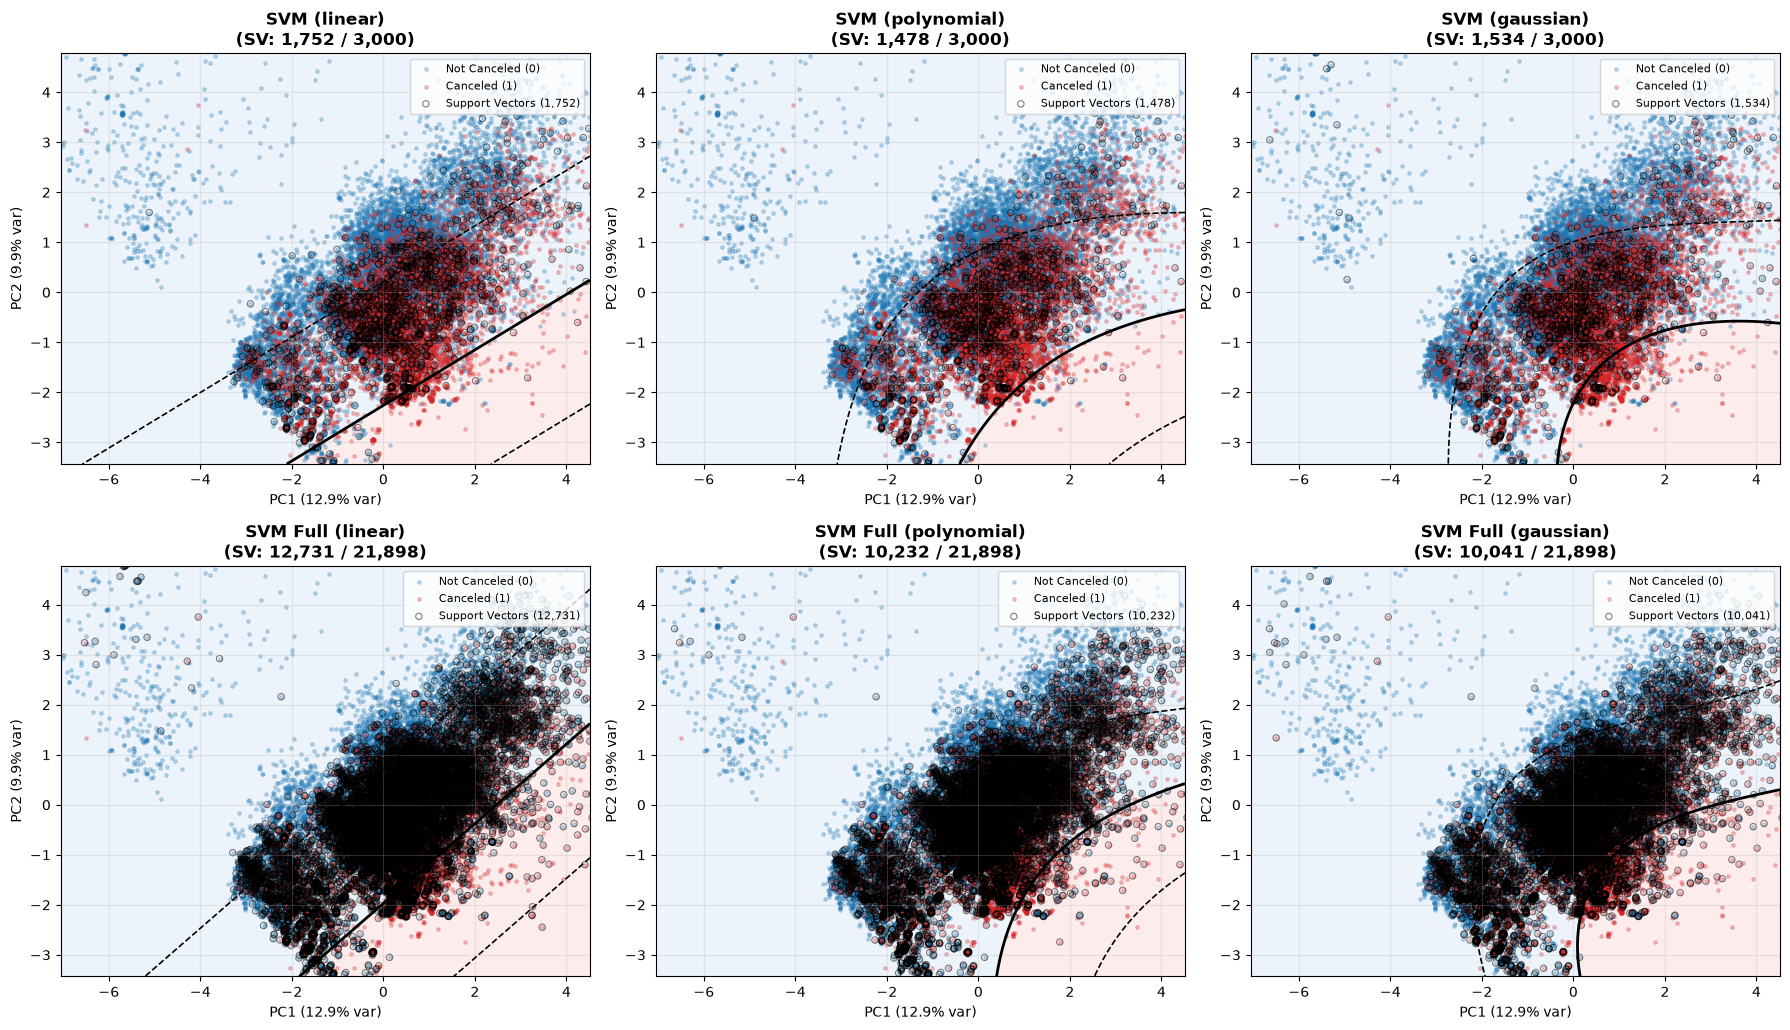

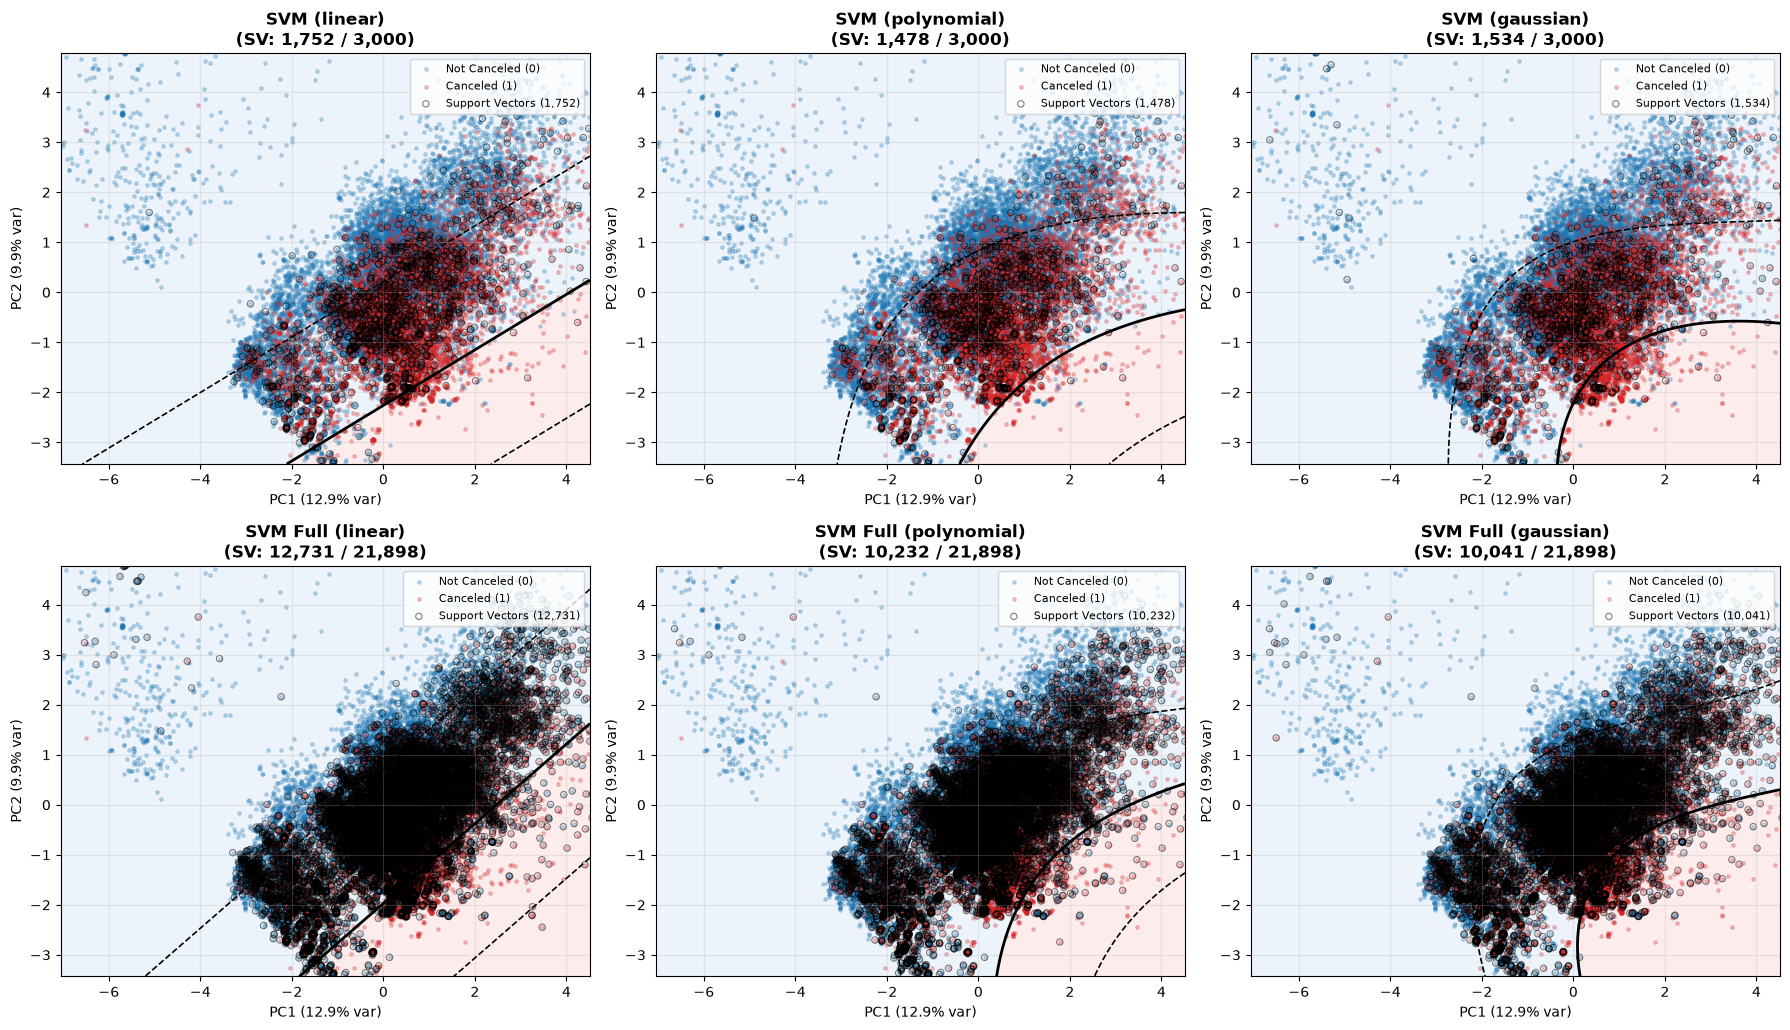

In [ ]:
svm_vis= {k: m for k, m in fitted_models.items() if isinstance(m, SVM)}

plot_svm_2d(
    svm_vis,
    X_train,
    y_train,
    limit=None,     
    sv_limit=None,  
    output_path=CFG.OUTPUT_DIR / "svm_2d.png",
    show=True,      
    random_state=CFG.SEED,
)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [24]:
# Model Parameter
nb_params = dict(mode="discretized", alpha=1.0, n_bins=5, var_smoothing=1e-9)
nb_candidates = {
    "Naive Bayes": nb_params,
    "Naive Bayes (Gaussian)": dict(
        mode="gaussian", alpha=1.0, var_smoothing=1e-9, use_feature_weights=False,
    ),
    "Optimized Naive Bayes": dict(
        mode="mixed", alpha=1.0, var_smoothing=0.5, use_feature_weights=True,
    ),
}

# Training and Validation
for name, params in nb_candidates.items():
    model = NaiveBayes(**params).fit(X_train, y_train)
    predictions = model.predict(X_val)

    fitted_models[name] = model
    valid_predictions[name] = predictions

    print(f"{name}: validation accuracy = {np.mean(predictions == y_val.to_numpy()):.4f}")

# Visualize Bayesian Network Structure (Bonus: Graph of Feature & Class Relationships)
nb_graph_path = CFG.OUTPUT_DIR / "naive_bayes_network.png"
fitted_models["Optimized Naive Bayes"].plot_network(
    path=nb_graph_path, top_n=12, target_name=CFG.TARGET,
)
print(f"Saved Bayesian Network graph to {nb_graph_path}")
display(fitted_models["Naive Bayes"].get_probability_tables()["priors"].round(4))

Naive Bayes: validation accuracy = 0.7549
Naive Bayes (Gaussian): validation accuracy = 0.4086
Optimized Naive Bayes: validation accuracy = 0.7408
Saved Bayesian Network graph to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/naive_bayes_network.png


,frequency,prior_probability_P(v_j)
class,,
0,14723.0,0.6723
1,7175.0,0.3277


## Model Evaluation

This part compares the validation results of all models.

In [37]:
# Baseline
actual_y = y_val.to_numpy()
evaluation_predictions = {
    **valid_predictions,
}
evaluation_models = {
    **fitted_models,
}

# Class Metrics and Confusion Matrix
results = []
for name, predicted in evaluation_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_y, predicted, average="binary", pos_label=1, zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(actual_y, predicted, labels=[0, 1]).ravel()

    results.append({
        "model": name,
        "train_rows": (len(evaluation_models[name].alpha)
                       if name in evaluation_models and isinstance(evaluation_models[name], SVM)
                       else len(y_train)),
        "accuracy": accuracy_score(actual_y, predicted),
        "precision": precision, "recall": recall, "f1": f1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })

    print(name)
    display(pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=pd.Index([0, 1], name="Actual"),
        columns=pd.Index([0, 1], name="Predicted"),
    ))

# Sorted by Accuracy
scores = pd.DataFrame(results).set_index("model").sort_values(
    ["accuracy", "f1"], ascending=False, kind="stable",
)
display(scores.round(4))
winner = scores.index[0]
print(f"Selected model: {winner}")

KNN


Predicted,0,1
Actual,,
0,3269,412
1,491,1303


Decision Tree


Predicted,0,1
Actual,,
0,3343,338
1,518,1276


Optimized Decision Tree


Predicted,0,1
Actual,,
0,3311,370
1,475,1319


... (24 outputs left out)

SVM Full (gaussian)


Predicted,0,1
Actual,,
0,3368,313
1,620,1174


,train_rows,accuracy,precision,recall,f1,TN,FP,FN,TP
model,,,,,,,,,
Optimized Decision Tree,21898,0.8457,0.7809,0.7352,0.7574,3311,370,475,1319
Decision Tree,21898,0.8437,0.7906,0.7113,0.7488,3343,338,518,1276
KNN,21898,0.8351,0.7598,0.7263,0.7427,3269,412,491,1303
SVM Full (gaussian),21898,0.8296,0.7895,0.6544,0.7156,3368,313,620,1174
SVM Full (polynomial),21898,0.8144,0.7775,0.6076,0.6821,3369,312,704,1090
SVM (gaussian),3000,0.8077,0.7568,0.6087,0.6747,3330,351,702,1092
SVM (polynomial),3000,0.8042,0.7500,0.6037,0.6689,3320,361,711,1083
SVM Full (linear),21898,0.7965,0.7071,0.6472,0.6758,3200,481,633,1161
Logistic regression (L2),21898,0.7962,0.7170,0.6243,0.6675,3239,442,674,1120


Selected model: Optimized Decision Tree


## Improvements

This part includes:
1. Hyperparameter Tuning
2. 5-Fold Cross-Validation

In [38]:
# Configuration and Parameter Tuning Function
tuning_selection = {
    "KNN": "KNN",
    "Tree": "Optimized Decision Tree",
    "LR": "Optimized logistic regression (l2)",
    "SVM": "SVM (gaussian)",
    "NB": "Optimized Naive Bayes",
}
tuning_grid = {
    "KNN": {"n_neighbors": [3, 5, 9]},
    "Tree": {
        "max_depth": [8, 10, 12, 14],
        "min_samples_leaf": [5, 10, 20],
        "min_samples_split": [10, 20],
        "ccp_alpha": [0.0, 0.0005, 0.001],
    },
    "LR": {"alpha": [0.0001, 0.001, 0.01]},
    "SVM": {"c": [0.1, 1.0, 10.0]},
    "NB": {
        "alpha": [0.1, 1.0, 5.0, 10.0],
        "var_smoothing": [1e-9, 0.1, 0.5],
        "use_feature_weights": [False, True],
    },
}
tuning_svm_limit = 3000
tuning_families = {
    KNN: "KNN", DecisionTree: "Tree", OptimizedTree: "Tree",
    LogisticRegression: "LR", LROptimized: "LR", SVM: "SVM", NaiveBayes: "NB",
}
tuning_winner = scores.index[0]
tuning_results = {}

# Each fold uses preprocessing learned only from its own training fold.
tuning_folds = []
for train_idx, check_idx in StratifiedKFold(
    n_splits=5, shuffle=True, random_state=CFG.SEED,
).split(X_train_raw, y_train):
    raw = X_train_raw.iloc[train_idx]
    state = fit_preparation(raw)
    tuning_folds.append((
        prepare(raw, state), y_train.iloc[train_idx],
        prepare(X_train_raw.iloc[check_idx], state), y_train.iloc[check_idx],
    ))


def tuning_fit_predict(name, params, X_fit, y_fit, X_check):
    model = type(evaluation_models[name])(**params)
    if isinstance(model, SVM):
        labels = y_fit.to_numpy()
        indices = np.arange(len(labels))

        if name in svm_params:
            limit = min(tuning_svm_limit, len(labels))
            kept, canceled = np.flatnonzero(labels == 0), np.flatnonzero(labels == 1)
            n_canceled = round(limit * len(canceled) / len(labels))
            rng = np.random.default_rng(CFG.SEED)
            indices = np.concatenate([
                rng.choice(kept, limit - n_canceled, replace=False),
                rng.choice(canceled, n_canceled, replace=False),
            ])
        
        model.fit(X_fit.to_numpy()[indices], 2 * labels[indices] - 1)
        predictions = [(model.predict(row) + 1) // 2 for row in X_check.to_numpy()]
    else:
        model.fit(X_fit, y_fit)
        predictions = model.predict(X_check)
    return model, np.asarray(predictions)


def tune_model(name):
    original = evaluation_models[name]
    family = tuning_families[type(original)]
    grid = tuning_grid[family]
    base = {key: getattr(original, key) for key in signature(type(original)).parameters}
    initial = {key: base[key] for key in grid}
    candidates = [initial] + [p for p in ParameterGrid(grid) if p != initial]
    rows = []
    for candidate in candidates:
        fold_scores = []
        try:
            for X_fit, y_fit, X_check, y_check in tuning_folds:
                _, pred = tuning_fit_predict(name, base | candidate, X_fit, y_fit, X_check)
                fold_scores.append(accuracy_score(y_check, pred))
        except (ValueError, RuntimeError) as error:
            print(f"{name} {candidate}: {error}")
            continue
        rows.append({"params": candidate, "mean_accuracy": np.mean(fold_scores),
                     "std_accuracy": np.std(fold_scores), "baseline": candidate == initial})
    if not rows:
        raise ValueError(f"All candidates fil for {name}")

    ranking = pd.DataFrame(rows).sort_values("mean_accuracy", ascending=False, kind="stable")
    print(name)
    display(ranking.reset_index(drop=True))
    best = ranking.iloc[0]
    model, pred = tuning_fit_predict(name, base | best["params"], X_train, y_train, X_val)
    return {"model": model, "predictions": pred, "params": best["params"],
            "mean_accuracy": best["mean_accuracy"], "std_accuracy": best["std_accuracy"]}


def tuning_metrics(predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val, predictions, average="binary", zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_val, predictions), "precision": precision,
            "recall": recall, "f1": f1, "TN": tn, "FP": fp, "FN": fn, "TP": tp}


/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]

In [39]:
# 2. Tune the best model from evaluation
tuning_results[tuning_winner] = tune_model(tuning_winner)

Optimized Decision Tree


,params,mean_accuracy,std_accuracy,baseline
0,"{'ccp_alpha': 0.0, 'max_depth': 10, 'min_sampl...",0.846516,0.002934,False
1,"{'ccp_alpha': 0.0, 'max_depth': 12, 'min_sampl...",0.846333,0.003622,False
2,"{'ccp_alpha': 0.0, 'max_depth': 12, 'min_sampl...",0.846242,0.002271,False
3,"{'ccp_alpha': 0.0, 'max_depth': 12, 'min_sampl...",0.846242,0.002271,False
4,"{'ccp_alpha': 0.0, 'max_depth': 10, 'min_sampl...",0.845603,0.004272,False
...,...,...,...,...
68,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.829208,0.002198,False
69,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.829208,0.002198,False
70,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.829208,0.002198,False
71,"{'ccp_alpha': 0.001, 'max_depth': 8, 'min_samp...",0.828295,0.001935,False


In [40]:
# 3. Compare baseline and tuned models on the same validation set
tuning_comparison = []
for name, result in tuning_results.items():
    old = tuning_metrics(evaluation_predictions[name])
    new = tuning_metrics(result["predictions"])
    tuning_comparison.append({
        "model": name, "params": result["params"], "cv_mean_accuracy": result["mean_accuracy"],
        "cv_std_accuracy": result["std_accuracy"], "delta_accuracy": new["accuracy"] - old["accuracy"],
    })
    print(name)
    display(pd.DataFrame([old, new], index=["Awal", "Tuned"]).round(4))

display(pd.DataFrame(tuning_comparison).set_index("model").round(4))

Optimized Decision Tree


,accuracy,precision,recall,f1,TN,FP,FN,TP
Awal,0.8457,0.7809,0.7352,0.7574,3311,370,475,1319
Tuned,0.8539,0.7817,0.7687,0.7752,3296,385,415,1379


,params,cv_mean_accuracy,cv_std_accuracy,delta_accuracy
model,,,,
Optimized Decision Tree,"{'ccp_alpha': 0.0, 'max_depth': 10, 'min_sampl...",0.8465,0.0029,0.0082


In [41]:
# 4. Run this to replace models when validation accuracy improves
for name, result in tuning_results.items():
    if name in fitted_models and name in valid_predictions:
        current_acc = accuracy_score(y_val, valid_predictions[name])
        tuned_acc = accuracy_score(y_val, result["predictions"])
        if tuned_acc > current_acc:
            fitted_models[name] = result["model"]
            valid_predictions[name] = result["predictions"]
            print(f"{name}: Accuracy {current_acc:.4f} -> {tuned_acc:.4f}")

Optimized Decision Tree: Accuracy 0.8457 -> 0.8539


In [42]:
# 5. Threshold tuning for DTL model based on 5-fold CV
final_positive_threshold = 0.5

if tuning_winner in tuning_results and isinstance(
    tuning_results[tuning_winner]["model"], (DecisionTree, OptimizedTree)
):
    tree_result = tuning_results[tuning_winner]
    original_tree = evaluation_models[tuning_winner]
    tree_base = {
        key: getattr(original_tree, key)
        for key in signature(type(original_tree)).parameters
    }
    thresholds = np.arange(0.30, 0.71, 0.05)
    threshold_scores = []

    for threshold in thresholds:
        fold_scores = []
        for X_fit, y_fit, X_check, y_check in tuning_folds:
            model = type(original_tree)(**(tree_base | tree_result["params"]))
            model.fit(X_fit, y_fit)
            probabilities = model.predict_proba(X_check)
            positive_index = list(model.classes_).index(1)
            predictions = (probabilities[:, positive_index] >= threshold).astype(int)
            fold_scores.append(accuracy_score(y_check, predictions))
        threshold_scores.append((float(threshold), float(np.mean(fold_scores))))

    threshold_ranking = pd.DataFrame(
        threshold_scores,
        columns=["threshold", "cv_mean_accuracy"],
    )
    threshold_ranking = threshold_ranking.sort_values(
        "cv_mean_accuracy", ascending=False, kind="stable"
    ).reset_index(drop=True)
    final_positive_threshold = float(threshold_ranking.iloc[0]["threshold"])

    tuned_tree = tree_result["model"]
    validation_probabilities = tuned_tree.predict_proba(X_val)
    positive_index = list(tuned_tree.classes_).index(1)
    threshold_predictions = (
        validation_probabilities[:, positive_index] >= final_positive_threshold
    ).astype(int)
    valid_predictions[tuning_winner] = threshold_predictions
    fitted_models[tuning_winner] = tuned_tree

    print("Decision Tree threshold tuning")
    display(threshold_ranking.head(10))
    print(f"Best threshold: {final_positive_threshold:.2f}")
    print(
        "Threshold validation accuracy:",
        f"{accuracy_score(y_val, threshold_predictions):.4f}",
    )

Decision Tree threshold tuning


,threshold,cv_mean_accuracy
0,0.55,0.845557
1,0.50,0.845237
2,0.45,0.844461
3,0.60,0.844324
4,0.65,0.842451
5,0.70,0.841766
6,0.40,0.838798
7,0.35,0.830898
8,0.30,0.820212


Best threshold: 0.55
Threshold validation accuracy: 0.8497


---

# Comparison with scikit-learn <a name="8"></a>

---

## Comparison 
This section compares each from-scratch model with its `scikit-learn` counterpart.

In [43]:
# Model Comparison
sklearn_models = {}
sklearn_predictions = {}
comparison_candidates = {}
comparison_results = []

def record_comparison(name, local_predictions, library_predictions, train_rows):
    for implementation, predicted in (("local", local_predictions), ("sklearn", library_predictions)):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_val, predicted, average="binary", pos_label=1, zero_division=0,
        )

        comparison_results.append({
            "model": name,
            "implementation": implementation,
            "train_rows": train_rows,
            "accuracy": accuracy_score(y_val, predicted),
            "precision": precision, "recall": recall, "f1": f1,
        })

# KNN
comparison_candidates["KNN"] = (
    KNeighborsClassifier(
        n_neighbors=fitted_models["KNN"].n_neighbors,
        weights="uniform", metric="euclidean", algorithm="brute",
    ), X_train, y_train, valid_predictions["KNN"],
)

# Decision Tree
for name, local_model in fitted_models.items():
    if isinstance(local_model, (DecisionTree, OptimizedTree)):
        comparison_candidates[name] = (
            DecisionTreeClassifier(**{
                parameter: getattr(local_model, parameter)
                for parameter in ("max_depth", "min_samples_split", "min_samples_leaf", "min_impurity_decrease", "ccp_alpha", "max_features", "random_state")
            }), X_train, y_train, valid_predictions[name],
        )

# Logistic Regression
for name in lr_candidates:
    local_model = fitted_models[name]
    comparison_candidates[name] = (
        SklearnLR(
            solver="saga",
            C=1.0 / (len(y_train) * local_model.alpha),
            l1_ratio=(1.0 if local_model.penalty == "l1" else local_model.l1_ratio if local_model.penalty == "elasticnet" else 0.0),
            max_iter=local_model.max_iter, tol=local_model.tol,
            random_state=local_model.random_state, class_weight=local_model.class_weight,
        ), X_train, y_train, valid_predictions[name],
    )

# Naive Bayes
for name, local_model in fitted_models.items():
    if isinstance(local_model, NaiveBayes):
        if local_model.mode in ("discretized", "categorical") and local_model.discretizer_ is not None:
            nb_encoder = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            )
            X_train_disc = local_model.discretizer_.transform(X_train).astype(str)
            X_val_disc = local_model.discretizer_.transform(X_val).astype(str)
            X_train_cat = pd.DataFrame(
                nb_encoder.fit_transform(X_train_disc),
                index=X_train.index,
                columns=X_train.columns,
            )
            X_val_cat = pd.DataFrame(
                np.clip(nb_encoder.transform(X_val_disc), 0, None),
                index=X_val.index,
                columns=X_val.columns,
            )
            cat_nb = CategoricalNB(alpha=local_model.alpha)
            cat_nb.fit(X_train_cat, y_train)
            cat_pred = cat_nb.predict(X_val_cat)
            sklearn_models[name] = cat_nb
            sklearn_predictions[name] = cat_pred
            record_comparison(name, valid_predictions[name], cat_pred, len(y_train))
        else:
            comparison_candidates[name] = (
                GaussianNB(var_smoothing=local_model.var_smoothing),
                X_train,
                y_train,
                valid_predictions[name],
            )

# SVM
for name, local_model in fitted_models.items():
    if isinstance(local_model, SVM):
        comparison_candidates[name] = (
            SVC(
                C=local_model.c,
                kernel={"linear": "linear", "polynomial": "poly", "gaussian": "rbf"}[local_model.kernel],
                gamma=local_model.gamma, degree=local_model.p, coef0=local_model.r,
                tol=1e-6,
            ),
            X_svm if name in svm_params else X_train,
            y_svm if name in svm_params else 2 * y_train.to_numpy() - 1,
            valid_predictions[name],
        )

# Training and Validation
for name, (comparison_model, train_matrix, train_labels, local_predictions) in comparison_candidates.items():
    comparison_model.fit(train_matrix, train_labels)
    predicted = comparison_model.predict(
        X_val if isinstance(train_matrix, pd.DataFrame) else X_val.to_numpy()
    )

    if isinstance(comparison_model, SVC):
        predicted = (predicted + 1) // 2

    sklearn_models[name] = comparison_model
    sklearn_predictions[name] = predicted
    record_comparison(name, local_predictions, predicted, len(train_labels))

# Comparison
comparison_scores = pd.DataFrame(comparison_results).set_index(["model", "implementation"])
display(comparison_scores.round(4))

/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


train_rows  \
model                                      implementation               
Naive Bayes                                local                21898   
                                           sklearn              21898   
KNN                                        local                21898   
                                           sklearn              21898   
Decision Tree                              local                21898   
                                           sklearn              21898   
Optimized Decision Tree                    local                21898   
                                           sklearn              21898   
Logistic regression (L2)                   local                21898   
                                           sklearn              21898   
Optimized logistic regression (l1)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (l2)         local                21898   
                                           sklearn              21898   
Optimized logistic regression (elasticnet) local                21898   
                                           sklearn              21898   
Naive Bayes (Gaussian)                     local                21898   
                                           sklearn              21898   
Optimized Naive Bayes                      local                21898   
                                           sklearn              21898   
SVM (linear)                               local                 3000   
                                           sklearn               3000   
SVM (polynomial)                           local                 3000   
                                           sklearn               3000   
SVM (gaussian)                             local                 3000   
                                           sklearn               3000   
SVM Full (linear)                          local                21898   
                                           sklearn              21898   
SVM Full (polynomial)                      local                21898   
                                           sklearn              21898   
SVM Full (gaussian)                        local                21898   
                                           sklearn              21898   

                                                           accuracy  \
model                                      implementation             
Naive Bayes                                local             0.7549   
                                           sklearn           0.7549   
KNN                                        local             0.8351   
                                           sklearn           0.8351   
Decision Tree                              local             0.8437   
                                           sklearn           0.8435   
Optimized Decision Tree                    local             0.8497   
                                           sklearn           0.8504   
Logistic regression (L2)                   local             0.7962   
                                           sklearn           0.7951   
Optimized logistic regression (l1)         local             0.7938   
                                           sklearn           0.7976   
Optimized logistic regression (l2)         local             0.7927   
                                           sklearn           0.7951   
Optimized logistic regression (elasticnet) local             0.7921   
                                           sklearn           0.7967   
Naive Bayes (Gaussian)                     local             0.4086   
                                           sklearn           0.4086   
Optimized Naive Bayes                      local             0.7408   
                                           sklearn           0.4921   
SVM (linear)  

## Visualization

This section contains of Comparison's Graph

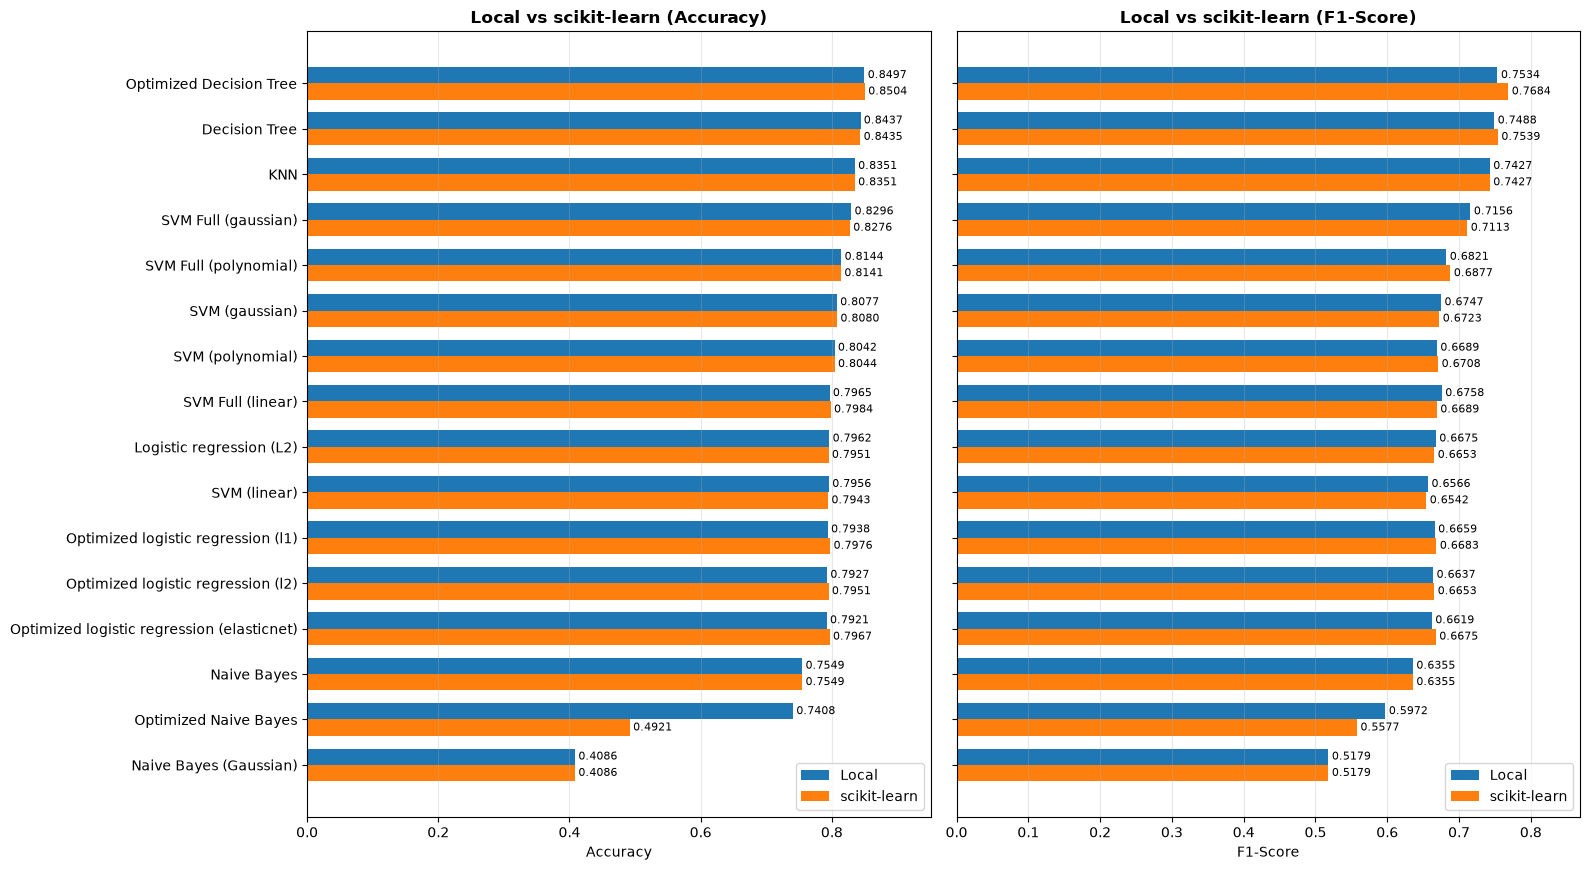

Saved comparison chart to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/sklearn_comparison.png


In [49]:
# Visualization
acc_piv = comparison_scores["accuracy"].unstack("implementation")[["local", "sklearn"]]
f1_piv = comparison_scores["f1"].unstack("implementation")[["local", "sklearn"]]

# Sorted
order = acc_piv.sort_values("local", ascending=True).index
acc_piv = acc_piv.loc[order]
f1_piv = f1_piv.loc[order]

y_pos = np.arange(len(order))
bar_h = 0.36

fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.55 * len(order))), sharey=True)

for ax, piv, metric_label in (
    (axes[0], acc_piv, "Accuracy"),
    (axes[1], f1_piv, "F1-Score"),
):
    bars_local = ax.barh(y_pos + bar_h / 2, piv["local"], height=bar_h, label="Local", color="#1f77b4")
    bars_skl = ax.barh(y_pos - bar_h / 2, piv["sklearn"], height=bar_h, label="scikit-learn", color="#ff7f0e")

    for bars in (bars_local, bars_skl):
        for bar in bars:
            w = bar.get_width()
            ax.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=8)

    ax.set_title(f"Local vs scikit-learn ({metric_label})", fontweight="bold")
    ax.set_xlabel(metric_label)
    ax.set_xlim(0, min(1.08, max(piv.max().max() + 0.10, 0.5)))
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(order)
plt.tight_layout()

# Output
comp_fig_path = CFG.OUTPUT_DIR / "sklearn_comparison.png"
fig.savefig(comp_fig_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved comparison chart to {comp_fig_path}")

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [44]:
# Save all models
model_dir = CFG.OUTPUT_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)

for name, model in fitted_models.items():
    model_path = model_dir / f"{name}.pkl"
    with model_path.open("wb") as file:
        pickle.dump(
            {"name": name, "model": model, "preparation": preparation},
            file,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    print(f"Saved {model_path}")


Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/KNN.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Decision Tree.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized Decision Tree.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Logistic regression (L2).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (l1).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (l2).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Optimized logistic regression (elasticnet).pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/models/Naive Bayes.pkl
Saved /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggl

In [35]:
# Choose model file
model_path = CFG.OUTPUT_DIR / "models" / "KNN.pkl"
with model_path.open("rb") as file:
    saved = pickle.load(file)

loaded_name = saved["name"]
loaded_model = saved["model"]
loaded_preparation = saved["preparation"]
print(f"Loaded {loaded_name}")


Loaded KNN


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [45]:
# Last Training Dataset
full_raw = train_df.drop(columns=[CFG.ID, CFG.TARGET])
full_y = train_df[CFG.TARGET].to_numpy(dtype=int)
final_preparation = fit_preparation(full_raw)
X_full = prepare(full_raw, final_preparation)
X_test_final = prepare(test_df.drop(columns=CFG.ID), final_preparation)

# Model Parameter
winner_model = fitted_models[winner]
final_params = {
    parameter: getattr(winner_model, parameter)
    for parameter in signature(type(winner_model)).parameters
}
if winner in tuning_results:
    final_params.update(tuning_results[winner]["params"])
if "random_state" in final_params:
    final_params["random_state"] = CFG.SEED

final_model = type(winner_model)(**final_params)

# Retrain on full training data
if isinstance(final_model, SVM):
    if winner in svm_params:
        rng = np.random.default_rng(CFG.SEED)
        limit = min(SVM_TRAIN_LIMIT, len(full_y))
        canceled = np.flatnonzero(full_y == 1)
        kept = np.flatnonzero(full_y == 0)
        n_canceled = round(limit * len(canceled) / len(full_y))
        indices = np.concatenate([
            rng.choice(kept, limit - n_canceled, replace=False),
            rng.choice(canceled, n_canceled, replace=False),
        ])
    else:
        indices = np.arange(len(full_y))
    final_model.fit(X_full.to_numpy()[indices], 2 * full_y[indices] - 1)
    test_predictions = np.array([
        (final_model.predict(row) + 1) // 2 for row in X_test_final.to_numpy()
    ], dtype=int)
else:
    final_model.fit(X_full, full_y)
    if isinstance(final_model, (DecisionTree, OptimizedTree)) and "final_positive_threshold" in globals():
        test_probabilities = final_model.predict_proba(X_test_final)
        positive_index = list(final_model.classes_).index(1)
        test_predictions = (
            test_probabilities[:, positive_index] >= final_positive_threshold
        ).astype(int)
    else:
        test_predictions = final_model.predict(X_test_final)

# Last Validation
sample = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv", dtype={CFG.ID: str})
if (not test_df[CFG.ID].is_unique or not sample[CFG.ID].is_unique or set(test_df[CFG.ID]) != set(sample[CFG.ID])):
    raise ValueError("Test IDs and sample_submission IDs must match and be unique.")

prediction_by_id = pd.Series(test_predictions, index=test_df[CFG.ID])
submission = sample[[CFG.ID]].assign(**{CFG.TARGET: sample[CFG.ID].map(prediction_by_id)})
if not submission[CFG.TARGET].isin([0, 1]).all():
    raise ValueError("Submission contains missing or invalid predictions.")

submission[CFG.TARGET] = submission[CFG.TARGET].astype(int)

# Export CSV
submission_path = CFG.OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Selected model: {winner}")
print(f"Wrote {len(submission):,} predictions to {submission_path}")
display(submission.head())

/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)
/tmp/ipykernel_14836/3763947774.py:27: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  frame["is_weekend_arrival"] = arrival_dates.dt.dayofweek.isin([4, 5, 6]).astype(float)


Selected model: Optimized Decision Tree
Wrote 6,844 predictions to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/submission.csv


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


## Error Analysis

This analysis examines the types of model errors observed on the validation set. Since the test set has no target labels, errors are analyzed using the validation set only.

The analysis supports each step taken in this notebook.

In [46]:
model_pred = np.asarray(valid_predictions[winner]).reshape(-1)
actual = y_val.to_numpy(dtype=int).reshape(-1)

error_frame = val_set.drop(columns=[CFG.TARGET], errors="ignore").copy()
error_frame["actual"] = actual
error_frame["predicted"] = model_pred
error_frame["error_type"] = np.select(
    [
        (error_frame["actual"] == 0) & (error_frame["predicted"] == 1),
        (error_frame["actual"] == 1) & (error_frame["predicted"] == 0),
    ],
    ["False Positive", "False Negative"],
    default="Correct",
)

error_counts = error_frame["error_type"].value_counts().rename("count").to_frame()
error_counts["share"] = error_counts["count"] / len(error_frame)
display(error_counts)

misclassified = error_frame[error_frame["error_type"] != "Correct"].copy()
print(f"Misclassified samples: {len(misclassified):,} out of {len(error_frame):,}")

for column in ["booking_channel", "room_category", "meal_package"]:
    if column in misclassified.columns:
        print(f"\nDistribution of {column} in misclassified predictions")
        display(pd.crosstab(
            misclassified[column],
            misclassified["error_type"],
            normalize="columns",
        ).round(3))

numeric_error_columns = [
    "num_adults", "num_children", "weekend_nights", "weekday_nights",
    "days_before_arrival", "prior_cancellations",
    "prior_completed_bookings", "nightly_rate_idr", "special_requests",
]
numeric_error_columns = [
    column for column in numeric_error_columns
    if column in misclassified.columns
]

print("\nMedian comparison of numeric features")
display(error_frame.groupby("error_type")[numeric_error_columns].median().T)

display_columns = [
    CFG.ID, "actual", "predicted", "error_type", "booking_channel",
    "room_category", "meal_package", "days_before_arrival",
    "nightly_rate_idr", "special_requests",
]
display_columns = [column for column in display_columns if column in misclassified.columns]
display(misclassified[display_columns].head(20))


,count,share
error_type,,
Correct,4652,0.849680
False Negative,537,0.098082
False Positive,286,0.052237


Misclassified samples: 823 out of 5,475

Distribution of booking_channel in misclassified predictions


error_type,False Negative,False Positive
booking_channel,,
Airline,0.006,0.000
Complimentary,0.000,0.003
Corporate,0.045,0.007
Offline Agent,0.199,0.175
Online Travel Agent,0.750,0.815



Distribution of room_category in misclassified predictions


error_type,False Negative,False Positive
room_category,,
Type A,0.027,0.029
Type B,0.770,0.653
Type C,0.004,0.014
Type D,0.019,0.014
Type E,0.002,0.000
Type F,0.006,0.004
Type G,0.173,0.285



Distribution of meal_package in misclassified predictions


error_type,False Negative,False Positive
meal_package,,
Breakfast,0.764,0.715
Half Board,0.073,0.063
Room Only,0.163,0.222



Median comparison of numeric features


error_type,Correct,False Negative,False Positive
num_adults,2.0,2.0,2.0
num_children,0.0,0.0,0.0
weekend_nights,1.0,1.0,1.0
weekday_nights,2.0,2.0,2.0
days_before_arrival,57.0,66.0,76.0
prior_cancellations,0.0,0.0,0.0
prior_completed_bookings,0.0,0.0,0.0
nightly_rate_idr,1639500.0,1569000.0,1837000.0
special_requests,0.0,0.0,0.0


,id,actual,predicted,error_type,booking_channel,room_category,meal_package,days_before_arrival,nightly_rate_idr,special_requests
10423,42e62546,1,0,False Negative,Online Travel Agent,Type B,Breakfast,63.0,1297000.0,0.0
2952,fa10d9f1,1,0,False Negative,Online Travel Agent,Type B,Breakfast,35.0,1797000.0,1.0
23612,5d7b59e2,0,1,False Positive,Offline Agent,Type B,Breakfast,286.0,NaN,0.0
1286,eeb67527,1,0,False Negative,Online Travel Agent,Type D,Breakfast,8.0,1378000.0,1.0
16320,23a66a27,1,0,False Negative,Online Travel Agent,Type A,Breakfast,75.0,2619000.0,1.0
16300,88c86ca4,0,1,False Positive,Online Travel Agent,Type B,Breakfast,54.0,1894000.0,1.0
15311,1079536a,0,1,False Positive,Online Travel Agent,Type G,Half Board,147.0,1952000.0,0.0
23916,ccf703df,0,1,False Positive,Online Travel Agent,NaN,Breakfast,38.0,1579000.0,NaN
19630,369be487,1,0,False Negative,Online Travel Agent,Type B,Breakfast,53.0,1326000.0,2.0
16130,0f190f24,0,1,False Positive,Online Travel Agent,Type G,Breakfast,NaN,3063000.0,0.0


---

# Cost-Sensitive Classification <a name="12"></a>

---

In hotel booking cancellation prediction (`is_canceled`), the two types of classification errors carry asymmetric business costs:

- **False Positive ($\text{FP}$ - Predicted Canceled `1`, Actual Not Canceled `0`)**: The hotel expects the guest to cancel and releases the room to another customer (*overbooking*). When the original guest arrives, the property becomes **overbooked**, incurring severe costs (guest relocation, compensation, and reputational damage). Its relative cost is assumed to be **$C_{FP} = 2$**.
- **False Negative ($\text{FN}$ - Predicted Not Canceled `0`, Actual Canceled `1`)**: The hotel holds a room for a guest who eventually cancels, resulting in an unsold room opportunity cost with a baseline weight of **$C_{FN} = 1$**.

### How Our Approach Changes for This Task

1. **Decision Threshold Shifting (*Bayesian Minimum Expected Cost Rule*)**:
   Under *Bayes Decision Theory*, the expected risk (cost) of predicting the positive class ($\hat{y}=1$) versus the negative class ($\hat{y}=0$) for an instance $\mathbf{x}$ with posterior probability $p = P(y=1 \mid \mathbf{x})$ is:
   $$R(\hat{y}=1 \mid \mathbf{x}) = C_{FP} \cdot (1 - p), \qquad R(\hat{y}=0 \mid \mathbf{x}) = C_{FN} \cdot p$$
   We predict a cancellation ($\hat{y}=1$) if and only if the expected cost of predicting cancellation is less than or equal to the expected cost of predicting non-cancellation:
   $$C_{FP}(1 - p) \le C_{FN} p \iff p \ge \tau^* = \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{2}{2 + 1} = \frac{2}{3} \approx 0.6667$$
   Consequently, the decision threshold is raised from $\tau = 0.50$ to **$\tau^* = 2/3 \approx 0.6667$**, making the classifier more conservative before flagging a reservation as canceled.

2. **Empirical Threshold Optimization & Cost-Driven Model Selection**:
   Instead of evaluating and selecting models purely by *Accuracy* or *F1-Score*, the evaluation objective shifts to directly minimizing the **Total Misclassification Cost**:
   $$\text{Total Cost}(\tau) = C_{FP} \cdot \text{FP}(\tau) + C_{FN} \cdot \text{FN}(\tau) = 2 \cdot \text{FP}(\tau) + 1 \cdot \text{FN}(\tau)$$

In [47]:
from src.naive_bayes import (
    compute_cost_sensitive_threshold,
    evaluate_classification_metrics,
)

COST_FP = 2.0
COST_FN = 1.0
bayes_threshold = compute_cost_sensitive_threshold(cost_fp=COST_FP, cost_fn=COST_FN)
print(f"Theoretical Bayes Optimal Threshold (C_FP={COST_FP:.0f}, C_FN={COST_FN:.0f}): {bayes_threshold:.4f} (2/3)")

actual_val = y_val.to_numpy(dtype=int)
threshold_grid = np.linspace(0.10, 0.90, 81)

cost_comparison_rows = []
model_threshold_curves = {}

for name, model in fitted_models.items():
    if not hasattr(model, "predict_proba"):
        continue

    proba_matrix = np.asarray(model.predict_proba(X_val), dtype=float)
    if proba_matrix.ndim == 2:
        if hasattr(model, "classes_"):
            pos_idx = list(model.classes_).index(1)
        elif hasattr(model, "classes") and model.classes is not None:
            pos_idx = list(model.classes).index(1)
        else:
            pos_idx = 1
        pos_proba = proba_matrix[:, pos_idx]
    else:
        pos_proba = proba_matrix.reshape(-1)

    # 1. Standard Threshold (0.50)
    pred_std = (pos_proba >= 0.50).astype(int)
    m_std = evaluate_classification_metrics(actual_val, pred_std, cost_fp=COST_FP, cost_fn=COST_FN)

    # 2. Theoretical Bayes Cost-Sensitive Threshold (2/3 ~ 0.6667)
    pred_bayes = (pos_proba >= bayes_threshold).astype(int)
    m_bayes = evaluate_classification_metrics(actual_val, pred_bayes, cost_fp=COST_FP, cost_fn=COST_FN)

    # 3. Empirical Cost-Minimizing Threshold on Validation Set
    curve_costs, curve_fps, curve_fns = [], [], []
    for t in threshold_grid:
        pred_t = (pos_proba >= t).astype(int)
        mt = evaluate_classification_metrics(actual_val, pred_t, cost_fp=COST_FP, cost_fn=COST_FN)
        curve_costs.append(mt["total_cost"])
        curve_fps.append(mt["fp"])
        curve_fns.append(mt["fn"])

    best_t_idx = int(np.argmin(curve_costs))
    emp_threshold = float(threshold_grid[best_t_idx])
    pred_emp = (pos_proba >= emp_threshold).astype(int)
    m_emp = evaluate_classification_metrics(actual_val, pred_emp, cost_fp=COST_FP, cost_fn=COST_FN)

    model_threshold_curves[name] = {
        "thresholds": threshold_grid,
        "costs": np.array(curve_costs),
        "fps": np.array(curve_fps),
        "fns": np.array(curve_fns),
        "emp_threshold": emp_threshold,
    }

    for strategy, thresh_val, metrics_dict in (
        ("Standard (t=0.50)", 0.50, m_std),
        ("Bayes Cost-Sensitive (t=0.67)", bayes_threshold, m_bayes),
        (f"Empirical Optimal (t={emp_threshold:.2f})", emp_threshold, m_emp),
    ):
        cost_saved = m_std["total_cost"] - metrics_dict["total_cost"]
        cost_saved_pct = (cost_saved / m_std["total_cost"] * 100.0) if m_std["total_cost"] > 0 else 0.0
        cost_comparison_rows.append({
            "model": name,
            "strategy": strategy,
            "threshold": round(thresh_val, 4),
            "FP (Overbooked)": metrics_dict["fp"],
            "FN (Empty Room)": metrics_dict["fn"],
            "Total Cost (2*FP+FN)": metrics_dict["total_cost"],
            "Cost Saved": cost_saved,
            "Cost Reduction (%)": round(cost_saved_pct, 2),
            "accuracy": round(metrics_dict["accuracy"], 4),
            "precision": round(metrics_dict["precision"], 4),
            "recall": round(metrics_dict["recall"], 4),
            "f1": round(metrics_dict["f1"], 4),
        })

cost_comparison_df = pd.DataFrame(cost_comparison_rows).set_index(["model", "strategy"])
display(cost_comparison_df)

Theoretical Bayes Optimal Threshold (C_FP=2, C_FN=1): 0.6667 (2/3)


threshold  \
model                                      strategy                                   
Decision Tree                              Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.73)        0.7300   
Optimized Decision Tree                    Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.72)        0.7200   
Logistic regression (L2)                   Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.67)        0.6700   
Optimized logistic regression (l1)         Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.76)        0.7600   
Optimized logistic regression (l2)         Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.73)        0.7300   
Optimized logistic regression (elasticnet) Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.70)        0.7000   
Naive Bayes                                Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.83)        0.8300   
Naive Bayes (Gaussian)                     Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.89)        0.8900   
Optimized Naive Bayes                      Standard (t=0.50)                 0.5000   
                                           Bayes Cost-Sensitive (t=0.67)     0.6667   
                                           Empirical Optimal (t=0.90)        0.9000   

                                                                          FP (Overbooked)  \
model                                      strategy                                         
Decision Tree                              Standard (t=0.50)                          350   
                                           Bayes Cost-Sensitive (t=0.67)              210   
                                           Empirical Optimal (t=0.73)                 148   
Optimized Decision Tree                    Standard (t=0.50)                          399   
                                           Bayes Cost-Sensitive (t=0.67)              214   
                                           Empirical Optimal (t=0.72)                 202   
Logistic regression (L2)                   Standard (t=0.50)                          442   
                                           Bayes Cost-Sensitive (t=0.67)              185   
                                           Empirical Optimal (t=0.67)                 180   
Optimized logistic regression (l1)         Standard (t=0.50)                          460   
                                           Bayes Cost-Sensitive (t=0.67)              206   
                                           Empirical Optimal (t=0.76)                 111   
Optimized logistic regression (l2)         Standard (t=0.50)                          461   
                                           Bayes Cost-Sensitive (t=0.67)              220   
                                           Empirical Optimal (

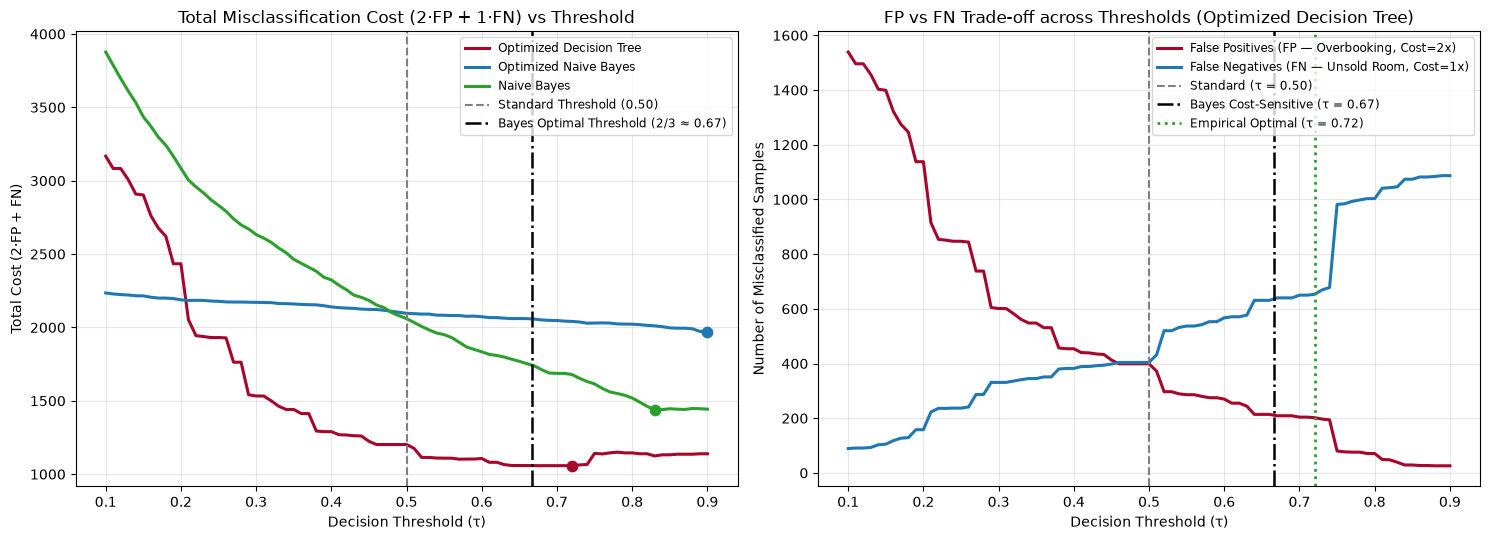

Saved cost-sensitive analysis figure to /home/leains/Desktop/ITB/SEM_5/AI/TUBES/IF3170_G22_OISCDivisiKaggle/output/cost_sensitive_analysis.png


In [48]:
# Visualize Total Cost Curve and FP vs FN Trade-off across Decision Thresholds
plot_candidates = [
    m for m in (winner, "Optimized Naive Bayes", "Naive Bayes")
    if m in model_threshold_curves
]

# Deduplicate while preserving order
plot_models = list(dict.fromkeys(plot_candidates))
target_curve_model = plot_models[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: Total Cost (2*FP + FN) vs Decision Threshold
ax1 = axes[0]
palette = ["#a8052b", "#1f77b4", "#2ca02c", "#ff7f0e"]
for idx, m_name in enumerate(plot_models):
    c_data = model_threshold_curves[m_name]
    color = palette[idx % len(palette)]
    ax1.plot(c_data["thresholds"], c_data["costs"], label=f"{m_name}", color=color, linewidth=2.2)
    emp_t = c_data["emp_threshold"]
    min_c = float(np.min(c_data["costs"]))
    ax1.scatter([emp_t], [min_c], color=color, s=55, zorder=5)

ax1.axvline(0.50, color="gray", linestyle="--", linewidth=1.5, label="Standard Threshold (0.50)")
ax1.axvline(bayes_threshold, color="black", linestyle="-.", linewidth=1.8, label="Bayes Optimal Threshold (2/3 ≈ 0.67)")
ax1.set_title("Total Misclassification Cost (2·FP + 1·FN) vs Threshold")
ax1.set_xlabel("Decision Threshold (τ)")
ax1.set_ylabel("Total Cost (2·FP + FN)")
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Panel 2: False Positive (Overbooking) vs False Negative Trade-off on Primary Model
ax2 = axes[1]
main_curve = model_threshold_curves[target_curve_model]
ax2.plot(
    main_curve["thresholds"], main_curve["fps"],
    color="#a8052b", linewidth=2.2, label="False Positives (FP — Overbooking, Cost=2x)",
)
ax2.plot(
    main_curve["thresholds"], main_curve["fns"],
    color="#1f77b4", linewidth=2.2, label="False Negatives (FN — Unsold Room, Cost=1x)",
)
ax2.axvline(0.50, color="gray", linestyle="--", linewidth=1.5, label="Standard (τ = 0.50)")
ax2.axvline(bayes_threshold, color="black", linestyle="-.", linewidth=1.8, label="Bayes Cost-Sensitive (τ = 0.67)")
ax2.axvline(
    main_curve["emp_threshold"], color="#2ca02c", linestyle=":", linewidth=2.0,
    label=f"Empirical Optimal (τ = {main_curve["emp_threshold"]:.2f})",
)
ax2.set_title(f"FP vs FN Trade-off across Thresholds ({target_curve_model})")
ax2.set_xlabel("Decision Threshold (τ)")
ax2.set_ylabel("Number of Misclassified Samples")
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
cost_fig_path = CFG.OUTPUT_DIR / "cost_sensitive_analysis.png"
fig.savefig(cost_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved cost-sensitive analysis figure to {cost_fig_path}")

### Cost-Sensitive Classification Analysis

Based on the experiments and visualizations above, when a *False Positive* is $2\times$ as costly as a *False Negative* ($C_{FP} = 2, C_{FN} = 1$), our handling of this task changes across **4 key dimensions**:

1. **Decision Threshold Adjustment ($\tau = 0.50 \to \tau^* = 2/3 \approx 0.67$)**:
   - At the standard $\tau = 0.50$ cutoff, models treat overbooking errors ($\text{FP}$) and empty-room errors ($\text{FN}$) equally.
   - By raising the decision threshold to $\tau^* = 2/3$ (or the empirically tuned $\tau_{\text{opt}}$ via cross-validation), a booking is only predicted as canceled when the model is at least $66.7\%$ confident ($P(\text{is\_canceled}=1 \mid \mathbf{x}) \ge 2/3$).
   - As a result, **False Positives (Overbookings) drop substantially** and positive-class **Precision** increases significantly, while the modest increase in *False Negatives* is outweighed by the $2\times$ cost savings from avoided overbookings.

2. **Cost-Driven Evaluation & Model Selection**:
   - The primary criterion for hyperparameter tuning and selecting the winning model shifts from maximizing *Accuracy* or *F1-Score* to **minimizing Total Expected Cost** ($2 \cdot \text{FP} + 1 \cdot \text{FN}$).
   - Two models with similar accuracy can exhibit very different operational costs if one produces more *False Positives* than *False Negatives*.

3. **In-Processing Training Adjustments (*Class Weighting & Prior Scaling*)**:
   - In addition to post-hoc threshold moving during inference, the $C_{FP}:C_{FN} = 2:1$ cost ratio can be embedded directly into model training:
     - In **Naive Bayes**, this is mathematically equivalent to scaling the non-canceled prior $P(v=0)$ by $C_{FP}=2$ such that $\tilde{P}(v=0) \propto 2 P(v=0)$ and $\tilde{P}(v=1) \propto 1 P(v=1)$.
     - In **Logistic Regression**, **Decision Tree**, and **SVM**, this is achieved by setting asymmetric class weights `class_weight={0: 2.0, 1: 1.0}` (penalizing errors on actual non-canceled bookings twice as heavily during loss/impurity minimization).

4. **Operational Impact for Hotel Management**:
   - Under the cost-sensitive policy ($\tau \approx 0.67$), the hotel only reallocates or overbooks rooms for reservations with a high certainty of cancellation, effectively preventing guest walk-aways at check-in and reducing overall financial loss.